# Lab 01 · Exploring the station-hour table

**Roadmap P4.3 · Unit VI (PySpark) · CO4.** Before any model: what do the targets look like, how does
demand move through the day, and which features move with it?

Everything here reads `gold/ml_features`, written by the Scala `FeatureBuildJob`. It has one row per
station-hour of August (the fit split) and September (the test split), and each row's profile, graph and
archetype features come only from the eight weeks *before* its split (ARCHITECTURE §8.2). This lab looks at
the fit split only, so nothing seen here can leak into the choice of a model.

In [1]:
import matplotlib.pyplot as plt
from pyspark.ml.feature import VectorAssembler
from pyspark.ml.stat import Correlation
from pyspark.sql import functions as F

from velograph.common.serving import write_serving
from velograph.common.settings import data_paths
from velograph.lab.features import load_dictionary, load_splits
from velograph.lab.session import lab_session

SEED = 315
spark = lab_session("01-eda")
d = load_dictionary()
s = load_splits(spark)
print("Spark", spark.version, "·", spark.sparkContext.applicationId)
for w in d.report["windows"]:
    print(
        f"{w['split']:>4}: rows {w['rows']['from']}..{w['rows']['to']}, "
        f"features from {w['profile']['from']}..{w['profile']['to']}"
    )
print(
    "validation week (model selection only): "
    f"{d.report['validation']['from']}..{d.report['validation']['to']}"
)

Spark 3.5.8 · local-1792153372883
 fit: rows 2026-08-01..2026-08-31, features from 2026-06-06..2026-07-31
test: rows 2026-09-01..2026-09-30, features from 2026-07-07..2026-08-31
validation week (model selection only): 2026-08-25..2026-08-31


## 1. The targets are small counts, mostly zero

A station-hour sees about three departures on average, but almost half of all hours see none. The variance
is far above the mean (over-dispersion), the signature of a few very busy stations among many quiet ones.
That is why MAE, not only RMSE, is reported for every model: RMSE is dominated by the busiest hours.

In [2]:
fit = s.fit
stats = fit.agg(
    F.count(F.lit(1)).alias("rows"),
    F.avg("departures").alias("mean"),
    F.var_pop("departures").alias("variance"),
    F.avg((F.col("departures") == 0).cast("double")).alias("zero_share"),
).first()
print(
    f"{stats['rows']:,} fit rows · mean {stats['mean']:.3f} · variance {stats['variance']:.2f} · "
    f"zero hours {stats['zero_share'] * 100:.1f} %"
)

capped = F.when(F.col("departures") >= 10, "10+").otherwise(F.col("departures").cast("string"))
histogram = {r["value"]: r["count"] for r in fit.groupBy(capped.alias("value")).count().collect()}
order = [str(v) for v in range(10)] + ["10+"]
departures_histogram = [{"value": v, "share": round(histogram.get(v, 0) / stats["rows"], 5)} for v in order]
for row in departures_histogram:
    print(f"{row['value']:>3} departures: {row['share'] * 100:5.1f} %")

1,768,776 fit rows · mean 2.954 · variance 33.13 · zero hours 44.6 %


  0 departures:  44.6 %
  1 departures:  17.1 %
  2 departures:   9.1 %
  3 departures:   5.7 %
  4 departures:   4.0 %
  5 departures:   3.0 %
  6 departures:   2.4 %
  7 departures:   2.0 %
  8 departures:   1.6 %
  9 departures:   1.4 %
10+ departures:   9.0 %


## 2. Demand through the day

Mean departures and arrivals per station-hour, on working days and on days off (weekends and holidays).
Working days show the two commute peaks; days off one broad afternoon hump.

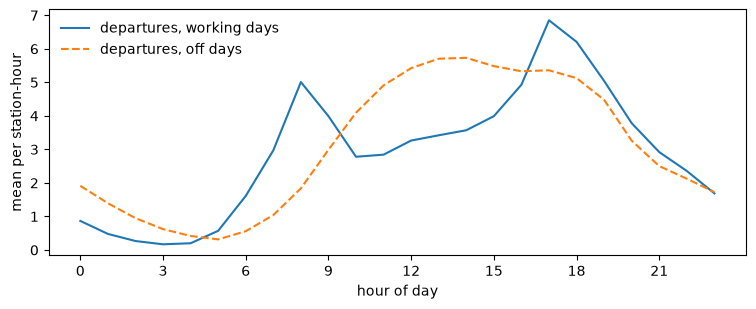

In [3]:
off = F.col("is_weekend") | F.col("is_holiday")
curves = (
    fit.groupBy(F.when(off, "off").otherwise("working").alias("day"), "hour")
    .agg(F.avg("departures").alias("departures"), F.avg("arrivals").alias("arrivals"))
    .orderBy("day", "hour")
    .collect()  # bounded: 2 x 24 rows
)
demand = {
    day: {
        target: [round(r[target], 4) for r in curves if r["day"] == day]
        for target in ("departures", "arrivals")
    }
    for day in ("working", "off")
}
fig, ax = plt.subplots(figsize=(9, 3.2))
for day, style in (("working", "-"), ("off", "--")):
    ax.plot(range(24), demand[day]["departures"], style, label=f"departures, {day} days")
ax.set_xlabel("hour of day")
ax.set_ylabel("mean per station-hour")
ax.set_xticks(range(0, 24, 3))
ax.legend(frameon=False)
plt.show()

## 3. Which features move with demand?

Pearson measures straight-line association; Spearman ranks both variables first, so it also catches
monotone but curved relations, and is not thrown by the few very large counts. `ml.stat.Correlation`
needs the columns in one vector, so a `VectorAssembler` comes first. A fixed 25 % sample keeps the
Spearman ranking pass cheap: the estimates are already stable at that size.

In [4]:
candidates = [*d.names(kinds={"numeric", "flag"}), "departures", "arrivals"]
sample = fit.sample(fraction=0.25, seed=SEED).persist()
# A column that never changes has no correlation at all (0 / 0): August has no holiday, for one.
spread = sample.agg(*[F.var_pop(F.col(c).cast("double")).alias(c) for c in candidates]).first()
constant = [c for c in candidates if not spread[c]]
columns = [c for c in candidates if c not in constant]
print("constant in the fit split, left out:", constant or "none")
vectors = VectorAssembler(inputCols=columns, outputCol="v").transform(sample).select("v").persist()
sample_rows = vectors.count()
pearson = Correlation.corr(vectors, "v", "pearson").first()[0].toArray()
spearman = Correlation.corr(vectors, "v", "spearman").first()[0].toArray()
target = columns.index("departures")
with_departures = sorted(
    (
        {
            "feature": c,
            "pearson": round(float(pearson[i, target]), 4),
            "spearman": round(float(spearman[i, target]), 4),
        }
        for i, c in enumerate(columns)
        if c not in ("departures", "arrivals")
    ),
    key=lambda r: -abs(r["spearman"]),
)
print(f"{sample_rows:,} sampled rows")
for r in with_departures[:12]:
    print(f"{r['feature']:>16}  Spearman {r['spearman']:+.3f}   Pearson {r['pearson']:+.3f}")

constant in the fit split, left out: ['is_holiday']


441,726 sampled rows
   prof_dep_mean  Spearman +0.765   Pearson +0.856
    prof_dep_std  Spearman +0.723   Pearson +0.753
   prof_arr_mean  Spearman +0.721   Pearson +0.779
    prof_arr_std  Spearman +0.681   Pearson +0.700
    out_strength  Spearman +0.627   Pearson +0.619
     in_strength  Spearman +0.627   Pearson +0.618
      pagerank_w  Spearman +0.580   Pearson +0.567
           pr_pm  Spearman +0.545   Pearson +0.494
           pr_am  Spearman +0.491   Pearson +0.471
        capacity  Spearman +0.466   Pearson +0.467
             lon  Spearman -0.328   Pearson -0.289
    humidity_pct  Spearman -0.288   Pearson -0.233


The hour-of-week profile mean is by far the strongest single signal: a station's own recent history at
this weekday and hour. That makes the **seasonal-naive** forecast (predict the profile mean) the baseline
every model in Lab 02 has to beat. Graph features (PageRank, strengths) carry the station's overall size;
weather moves demand much less than time does.

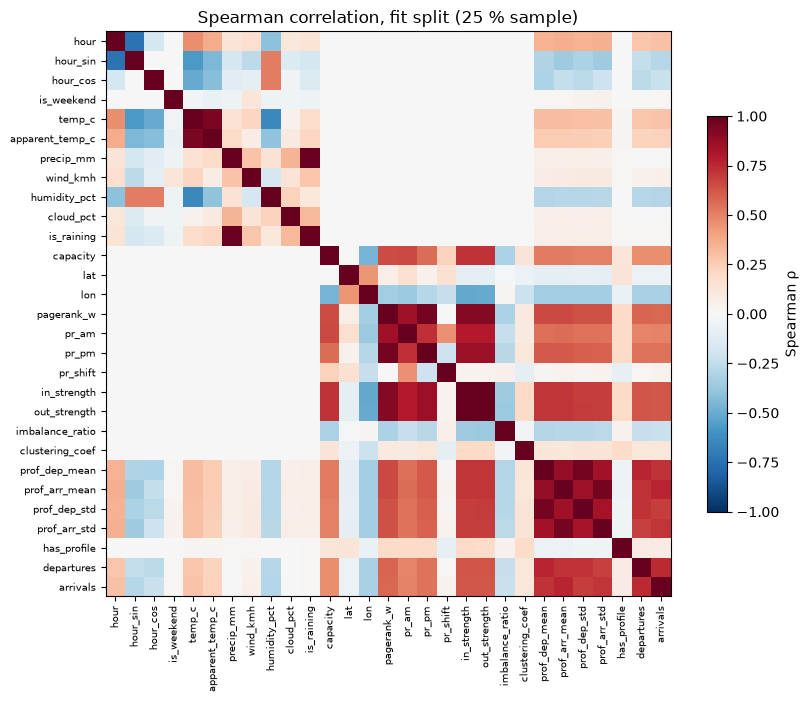

In [5]:
fig, ax = plt.subplots(figsize=(8.5, 7))
image = ax.imshow(spearman, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(columns)), columns, rotation=90, fontsize=7)
ax.set_yticks(range(len(columns)), columns, fontsize=7)
fig.colorbar(image, ax=ax, shrink=0.7, label="Spearman ρ")
ax.set_title("Spearman correlation, fit split (25 % sample)")
plt.tight_layout()
plt.show()

In [6]:
def matrix(m):
    return [[round(float(x), 4) for x in row] for row in m]


path = write_serving(
    data_paths().serving / "ml-correlation.json",
    "ml-correlation",
    "lab-01-eda",
    {
        "split": "fit",
        "sampleFraction": 0.25,
        "sampleRows": sample_rows,
        "columns": columns,
        "constant": constant,
        "pearson": matrix(pearson),
        "spearman": matrix(spearman),
        "withDepartures": with_departures,
        "demand": demand,
        "departuresHistogram": departures_histogram,
        "dispersion": {
            "rows": stats["rows"],
            "mean": round(stats["mean"], 4),
            "variance": round(stats["variance"], 4),
            "zeroShare": round(stats["zero_share"], 4),
        },
    },
    rows=sample_rows,
    source={"from": d.report["windows"][0]["rows"]["from"], "to": d.report["windows"][0]["rows"]["to"]},
)
print("wrote", path)

wrote C:\Users\Sayan\Desktop\int315\data\serving\ml-correlation.json


In [7]:
spark.stop()